<a href="https://colab.research.google.com/github/jaretorx/Proyecto-final-pia-modelado/blob/main/PIA_Modelado_Robot_Planar_2GDL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PIA | Modelado y simulación de un manipulador planar de 2 GDL
**UANL · FIME · Modelado y Simulación de Sistemas Mecatrónicos**  
**Duración de la simulación: 10 s**

Esta notebook implementa un manipulador planar RR de 2 grados de libertad en un plano **vertical**, alineado con la notación (Tabla 5.1) y convención del **Ejemplo 5.3** de Reyes Cortés (2020), incluyendo pares motores y fricción viscosa:

$$M(q)\ddot{q} + C(q,\dot{q})\dot{q} + g(q) + f(\dot{q}) = \tau$$

Se utiliza un control PD con compensación de gravedad como excitación de prueba para verificar la dinámica durante 10 segundos.

## 1. Parámetros del robot y configuración de simulación
Se emplean longitudes $l_1, l_2$ [m], centros de masa $l_{c1}, l_{c2}$ [m], masas $m_1, m_2$ [kg], inercias $I_1, I_2$ [$\text{kg}\cdot\text{m}^2$], gravedad $g$ [$\text{m/s}^2$] y coeficientes de fricción viscosa $b_1, b_2$ [$\text{N}\cdot\text{m}\cdot\text{s/rad}$].

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation

p = {
    "l1": 0.55,    # Longitud del eslabón 1 [m]
    "l2": 0.40,    # Longitud del eslabón 2 [m]
    "lc1": 0.275,  # Centro de masa del eslabón 1 [m]
    "lc2": 0.20,   # Centro de masa del eslabón 2 [m]
    "m1": 1.20,    # Masa del eslabón 1 [kg]
    "m2": 0.80,    # Masa del eslabón 2 [kg]
    "g": 9.81,     # Aceleración gravitacional [m/s^2]
    "b1": 0.12,    # Coeficiente de fricción viscosa articulación 1 [N·m·s/rad]
    "b2": 0.08,    # Coeficiente de fricción viscosa articulación 2 [N·m·s/rad]
}
p["I1"] = p["m1"] * (p["l1"] ** 2) / 12.0  # Inercia eslabón 1 [kg·m^2]
p["I2"] = p["m2"] * (p["l2"] ** 2) / 12.0  # Inercia eslabón 2 [kg·m^2]

# Ganancias de control PD con compensación de gravedad (excitación de prueba)
Kp = np.diag([24.0, 18.0])
Kd = np.diag([9.0, 7.0])

# Condiciones iniciales [q1, q2, dq1, dq2] y referencia deseada [rad]
q_deseada = np.array([np.pi / 3, -np.pi / 4])
x0 = np.array([2.5, 0.3, 0.0, 0.0])

print("Parámetros e inercias:", p)

Parámetros e inercias: {'l1': 0.55, 'l2': 0.4, 'lc1': 0.275, 'lc2': 0.2, 'm1': 1.2, 'm2': 0.8, 'g': 9.81, 'b1': 0.12, 'b2': 0.08, 'I1': 0.030250000000000003, 'I2': 0.01066666666666667}


## 2. Matrices del modelo dinámico Euler–Lagrange (Ejemplo 5.3)
Con $h = m_2 l_1 l_{c2} \sin(q_2)$ y $q_2$ medido de forma relativa al primer eslabón, se construyen $M(q)$, $C(q,\dot{q})$, $g(q)$ y $f(\dot{q})$.

In [21]:
def matrices(q, dq):
    q1, q2 = q
    dq1, dq2 = dq

    l1 = p["l1"]
    lc1 = p["lc1"]
    lc2 = p["lc2"]
    m1 = p["m1"]
    m2 = p["m2"]
    I1 = p["I1"]
    I2 = p["I2"]
    g = p["g"]
    b1 = p["b1"]
    b2 = p["b2"]

    h = m2 * l1 * lc2 * np.sin(q2)

    # Matriz de inercia M(q)
    M11 = m1 * (lc1 ** 2) + m2 * (l1 ** 2) + m2 * (lc2 ** 2) + 2.0 * m2 * l1 * lc2 * np.cos(q2) + I1 + I2
    M12 = m2 * (lc2 ** 2) + m2 * l1 * lc2 * np.cos(q2) + I2
    M21 = M12
    M22 = m2 * (lc2 ** 2) + I2
    M = np.array([[M11, M12], [M21, M22]], dtype=float)

    # Matriz de fuerzas centrípetas y de Coriolis C(q, dq)
    C = np.array([
        [-2.0 * h * dq2, -h * dq2],
        [h * dq1,         0.0]
    ], dtype=float)

    # Vector de pares gravitacionales g(q) del Ejemplo 5.3
    G = np.array([
        g * (lc1 * m1 * np.sin(q1) + m2 * l1 * np.sin(q1) + m2 * lc2 * np.sin(q1 + q2)),
        g * (lc2 * m2 * np.sin(q1 + q2))
    ], dtype=float)

    # Vector de fricción viscosa f(dq)
    F = np.array([b1 * dq1, b2 * dq2], dtype=float)

    return M, C, G, F


# Verificación de simetría y definida positiva de M(q)
for ang in np.linspace(-np.pi, np.pi, 9):
    M_test, _, _, _ = matrices(np.array([0.1, ang]), np.zeros(2))
    assert np.allclose(M_test, M_test.T)
    assert np.min(np.linalg.eigvalsh(M_test)) > 0.0
print("Comprobación: matriz M simétrica y definida positiva.")

Comprobación: matriz M simétrica y definida positiva.


## 3. Simulación numérica en Python (0 a 10 s)
Se integra el sistema con `scipy.integrate.solve_ivp` (`RK45`) resolviendo $M(q)\ddot{q} = \tau - C(q,\dot{q})\dot{q} - g(q) - f(\dot{q})$ mediante `np.linalg.solve`.

In [22]:
def ecuaciones_estado(t, x):
    q = x[:2]
    dq = x[2:]
    M, C, G, F = matrices(q, dq)
    tau = np.array([0.0, 0.0])
    ddq = np.linalg.solve(M, tau - C @ dq - G - F)
    return np.r_[dq, ddq]


t = np.linspace(0.0, 10.0, 1001)
sol = solve_ivp(
    ecuaciones_estado,
    t_span=(0.0, 10.0),
    y0=x0,
    t_eval=t,
    rtol=1e-9,
    atol=1e-11,
    max_step=0.02,
)
assert sol.success, sol.message

q = sol.y[:2]
dq = sol.y[2:]
error_final = np.rad2deg(q_deseada - q[:, -1])
print("Posiciones finales (grados):", np.round(np.rad2deg(q[:, -1]), 6))
print("Errores finales (grados):", np.round(error_final, 8))

Posiciones finales (grados): [1.473108 1.344594]
Errores finales (grados): [ 58.52689196 -46.34459382]


## 4. Respuesta angular de las articulaciones (0 a 10 s)

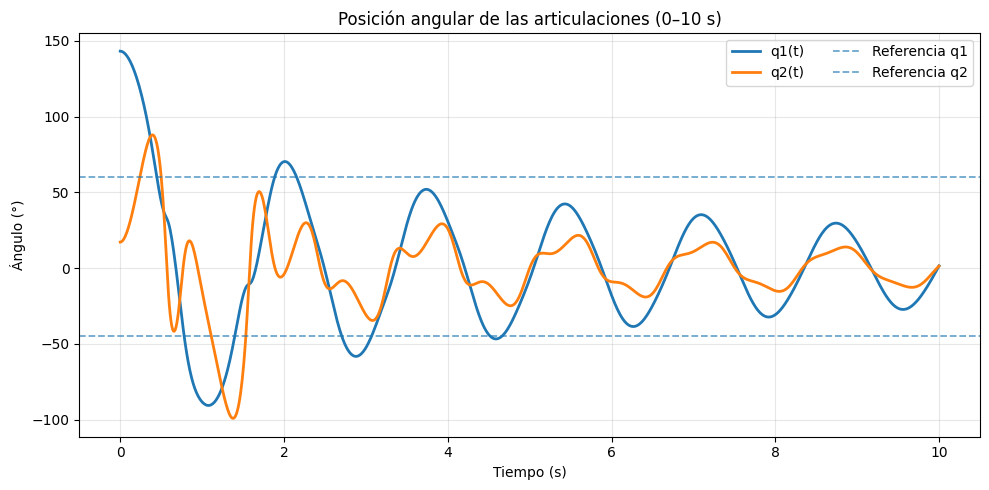

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t, np.rad2deg(q[0]), label="q1(t)", lw=2)
ax.plot(t, np.rad2deg(q[1]), label="q2(t)", lw=2)
for j in (0, 1):
    ax.axhline(
        np.rad2deg(q_deseada[j]),
        ls="--",
        lw=1.3,
        alpha=0.65,
        label=f"Referencia q{j + 1}",
    )
ax.set(
    xlabel="Tiempo (s)",
    ylabel="Ángulo (°)",
    title="Posición angular de las articulaciones (0–10 s)",
)
ax.grid(alpha=0.3)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 5. Evolución de los pares motores $\tau_1$ y $\tau_2$

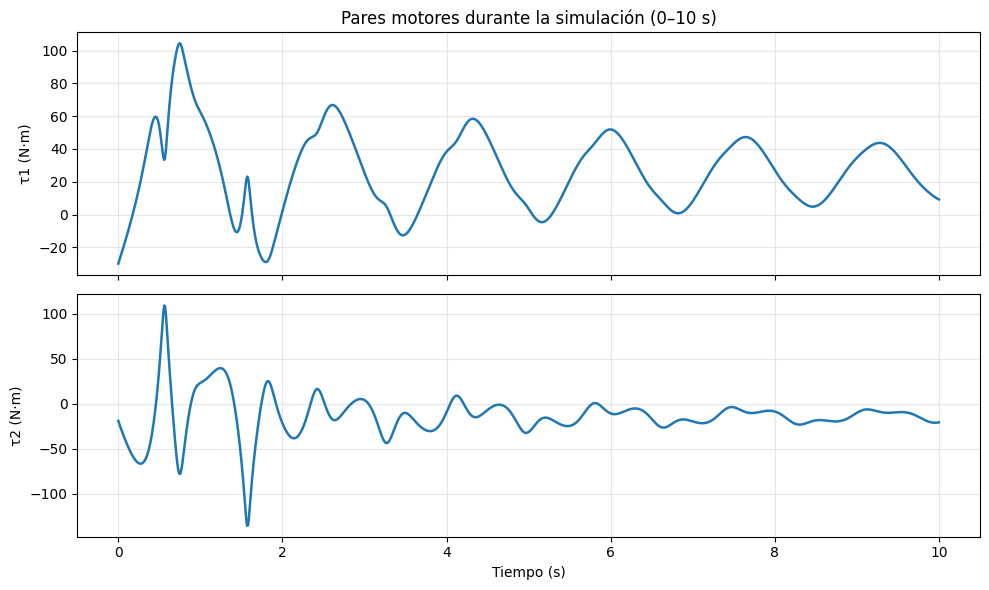

In [24]:
torques = np.array([
    matrices(q[:, i], dq[:, i])[2] + Kp @ (q_deseada - q[:, i]) - Kd @ dq[:, i]
    for i in range(len(t))
])

fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for j, ax in enumerate(axs):
    ax.plot(t, torques[:, j], lw=1.8)
    ax.set_ylabel(f"τ{j + 1} (N·m)")
    ax.grid(alpha=0.3)
axs[1].set_xlabel("Tiempo (s)")
axs[0].set_title("Pares motores durante la simulación (0–10 s)")
plt.tight_layout()
plt.show()

## 6. Posturas del manipulador en distintos instantes

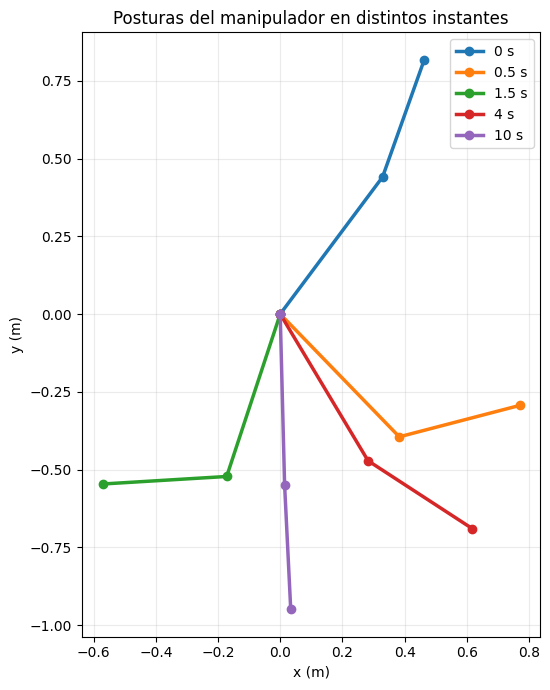

In [25]:
def puntos_robot(q):
    q1, q2 = q
    P0 = np.array([0.0, 0.0])
    P1 = P0 + p["l1"] * np.array([np.sin(q1), -np.cos(q1)])
    P2 = P1 + p["l2"] * np.array([np.sin(q1 + q2), -np.cos(q1 + q2)])
    return np.stack([P0, P1, P2])


fig, ax = plt.subplots(figsize=(7, 7))
for ti in [0, 0.5, 1.5, 4, 10]:
    idx = np.argmin(np.abs(t - ti))
    XY = puntos_robot(q[:, idx])
    ax.plot(XY[:, 0], XY[:, 1], "-o", lw=2.5, label=f"{ti:g} s")
ax.set_aspect("equal")
ax.set(xlabel="x (m)", ylabel="y (m)", title="Posturas del manipulador en distintos instantes")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Animación en Google Colab / Jupyter (opcional)

In [26]:
fig, ax = plt.subplots(figsize=(6, 6))
lim = p["l1"] + p["l2"] + 0.1
ax.set(
    xlim=(-lim, lim),
    ylim=(-lim, lim),
    xlabel="x (m)",
    ylabel="y (m)",
    title="Movimiento del manipulador (10 s)",
)
ax.set_aspect("equal")
ax.grid(alpha=0.2)
line, = ax.plot([], [], "-o", lw=5, markersize=8)
stamp = ax.text(0.05, 0.94, "", transform=ax.transAxes)


def actualizar(frame):
    X = puntos_robot(q[:, frame])
    line.set_data(X[:, 0], X[:, 1])
    stamp.set_text(f"t = {t[frame]:.2f} s")
    return line, stamp


anim = FuncAnimation(fig, actualizar, frames=np.arange(0, len(t), 10), interval=70, blit=True)
plt.close(fig)
display(HTML(anim.to_jshtml()))